# 2.1 Informe EDA — JobPath

**Análisis Exploratorio de Datos (EDA) · CRISP-DM fase 2 · KDD etapa de entendimiento**
**Minería de Datos · UNIMINUTO Ibagué · 2026-2**

Este cuaderno es el **informe EDA** del proyecto JobPath sobre el dataset enriquecido

`data/02_interim/empleos_con_competencias_limpio_sin_outliers.csv` (**341.090 × 23**, 69.182 personas),
la variante **sin cola larga** de JobHop v2 (test + val) enriquecida con la taxonomía **ESCO v1.2.1**.

> **Por qué existe este cuaderno.** El único EDA del repositorio (`2.0_EDA_y_seleccion.ipynb`) se ejecutó
> el **2026-09-15, antes** de integrar las seis columnas de competencias ESCO; su salida guardada ni las
> menciona. Este informe cubre el dataset enriquecido completo y cierra ese vacío.

Estructura (6 secciones): 1) ficha técnica · 2) univariado · 3) bivariado · 4) multivariado ·
5) competencias ESCO · 6) diagnóstico de calidad. Cierra con **hallazgos accionables**.

> **Nota de alcance.** Este EDA trabaja sobre la variante **ya recortada** (cola larga eliminada con IQR de
> Tukey, corte `dur_q ≥ 25` sobre el set completo). No hay contraste con el set con cola larga porque esa
> versión no está en disco: es un límite declarado, no un olvido.

## 0. Configuración y carga defensiva

Lectura defensiva (`dtype=str`, `keep_default_na=False`, `na_values=[""]`) para conservar los códigos con
ceros a la izquierda y los literales `'Present'` / `'None'` / `'unknown'` como texto. Los contadores ESCO
se convierten a número de forma explícita con `pd.to_numeric`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.grid": True,
    "grid.alpha": 0.30,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "figure.autolayout": False,
})

carpeta = Path.cwd()
while not (carpeta / "data").exists() and carpeta != carpeta.parent:
    carpeta = carpeta.parent
RAIZ = carpeta
CSV = RAIZ / "data" / "02_interim" / "empleos_con_competencias_limpio_sin_outliers.csv"
REPORT = RAIZ / "docs" / "explicacion" / "report"
REPORT.mkdir(parents=True, exist_ok=True)

SEED = 20262
rng = np.random.RandomState(SEED)

CONTADORES = ["n_skills_essential", "n_skills_competence", "n_skills_knowledge", "n_skills_sin_tipo"]

def guardar(fig, nombre):
    ruta = REPORT / nombre
    fig.savefig(ruta, dpi=150, bbox_inches="tight")
    print("figura ->", ruta.relative_to(RAIZ))

print("Raiz del proyecto:", RAIZ)
print("CSV:", CSV.relative_to(RAIZ), "|", round(CSV.stat().st_size / 1e6, 1), "MB")
print("matplotlib", matplotlib.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Raiz del proyecto: c:\Users\ASUS\Documents\MINERIA\MineriaProtect-SkillProccess
CSV: data\02_interim\empleos_con_competencias_limpio_sin_outliers.csv | 260.5 MB
matplotlib 3.11.2 | pandas 3.0.6 | numpy 2.5.4


In [2]:
df = pd.read_csv(CSV, dtype=str, encoding="utf-8", keep_default_na=False, na_values=[""])
print("Filas:", f"{len(df):,}", "| Columnas:", df.shape[1])
print("Personas (resume_id unicos):", f"{df['resume_id'].nunique():,}")

def trimestre(s):
    s = s.str.strip()
    out = pd.Series(np.nan, index=s.index)
    m = s.str.match(r"^Q[1-4] \d{4}$")
    out[m] = (s[m].str[-4:].astype(int) * 4 + s[m].str[1].astype(int)).astype(float)
    return out

df["start_ord"] = trimestre(df["start_date"])
df["end_ord"] = trimestre(df["end_date"])
df["dur_q"] = df["end_ord"] - df["start_ord"] + 1
assert (df["dur_q"].dropna() >= 1).all(), "duracion no positiva"

NUM = {c: pd.to_numeric(df[c], errors="coerce") for c in CONTADORES + ["veces_ese_oficio"]}
num = pd.DataFrame(NUM)
num["dur_q"] = df["dur_q"]
num["start_ord"] = df["start_ord"]
num["end_ord"] = df["end_ord"]

ok = df["saber_skills"].eq("ok")
print("saber_skills ->", df["saber_skills"].value_counts().to_dict())
print("Registros con el oficio clasificado (ok):", f"{int(ok.sum()):,}")

Filas: 341,090 | Columnas: 23
Personas (resume_id unicos): 69,182
saber_skills -> {'ok': 314904, 'no_clasificado': 26186}
Registros con el oficio clasificado (ok): 314,904


## 1. Ficha técnica y diccionario de datos

Grano del dataset: **una fila = una experiencia laboral** (un periodo en un oficio), no una persona ni un
oficio. `resume_id` agrupa las experiencias de una persona.

In [3]:
print("Dimensiones:", df.shape)
inicio = df["start_date"].replace("", np.nan).min()
print("Primer periodo (texto):", inicio)
print("Periodos distintos (persona, inicio, fin):",
      f"{df[['resume_id','start_date','end_date']].drop_duplicates().shape[0]:,}")
print()
print("=== Tipos inferidos por pandas (leidos como texto por diseno) ===")
print(df.dtypes.value_counts().to_string())
print()
print("=== Cardinalidad de columnas categoricas ===")
for c in ["university_level", "emparejado", "isco_group", "isco_group_label", "isco_level"]:
    print(f"{c:20s} valores distintos: {df[c].nunique():>6,}")
print(f"{'occupation_label':20s} valores distintos: {df['occupation_label'].nunique():>6,}")
print(f"{'occupation_code':20s} valores distintos: {df['occupation_code'].nunique():>6,}")

Dimensiones: (341090, 26)
Primer periodo (texto): Q1 1967
Periodos distintos (persona, inicio, fin): 323,742

=== Tipos inferidos por pandas (leidos como texto por diseno) ===
str        23
float64     3

=== Cardinalidad de columnas categoricas ===
university_level     valores distintos:      4
emparejado           valores distintos:      3
isco_group           valores distintos:    424
isco_group_label     valores distintos:    424
isco_level           valores distintos:      1
occupation_label     valores distintos:  2,826
occupation_code      valores distintos:  2,826


### Diccionario de columnas

| Columna | Tipo | Significado |
|---|---|---|
| `resume_id` | texto | Identificador de persona; agrupa su trayectoria |
| `start_date`, `end_date` | texto | Trimestre de inicio/fin (`Qn AAAA`); `end_date` = `'Present'` si el empleo seguía vigente (censura) |
| `university_level` | categórica | Máximo nivel educativo registrado |
| `matched_code` | texto | Código de ocupación crudo de JobHop v2 |
| `emparejado` | categórica | `ok` / `unknown` / `rescatado` (cobertura ESCO) |
| `occupation_code` | texto | Código ESCO/ISCO tras el cruce |
| `occupation_label` | texto | Nombre de la ocupación (ESCO) |
| `isco_group`, `isco_group_label`, `isco_level` | categórica | Área ocupacional jerárquica ISCO-08 |
| `n_skills_essential` | número | N.º de competencias esenciales que **exige** el oficio |
| `n_skills_competence` | número | Cuántas son *saber hacer* |
| `n_skills_knowledge` | número | Cuántas son *saber* |
| `n_skills_sin_tipo` | número | Relaciones sin `skillType` (bucket aritmético) |
| `veces_ese_oficio` | número | Cuántas veces esta persona ejerció **este** oficio (reincidencia) |
| `saber_skills` | categórica | `ok` / `no_clasificado`: si hay oficio al que atribuir competencias |
| `skills`, `knowledge`, `sin_tipo` | texto | Listas de nombres de competencias del oficio, separadas por `\|` |
| `es_unknown_ocupacion`, `es_rescatado`, `es_vigente` | booleana | Banderas de calidad y de censura |

> **Recuerda.** Las columnas de competencias describen el **puesto**, no a la persona: «el cargo exige N
> competencias», nunca «la persona sabe N cosas». La única columna conductual es `veces_ese_oficio`.

## 2. Análisis univariado

Medidas de tendencia central, dispersión y forma sobre las variables numéricas y frecuencias sobre las
categóricas. Con distribuciones asimétricas se reporta la **mediana** como medida de centro.

In [4]:
def resumen(serie):
    s = pd.to_numeric(serie, errors="coerce").dropna()
    q1, q3 = s.quantile(.25), s.quantile(.75)
    return pd.Series({
        "n": int(s.size), "media": round(s.mean(), 2), "mediana": round(s.median(), 2),
        "moda": round(s.mode().iloc[0], 2), "sd": round(s.std(), 2),
        "min": round(s.min(), 2), "Q1": round(q1, 2), "Q3": round(q3, 2),
        "IQR": round(q3 - q1, 2), "max": round(s.max(), 2),
        "asimetria": round(s.skew(), 3), "curtosis": round(s.kurt(), 3),
    })

tabla = pd.DataFrame({c: resumen(num[c]) for c in
                      ["dur_q", "n_skills_essential", "n_skills_competence",
                       "n_skills_knowledge", "n_skills_sin_tipo", "veces_ese_oficio"]}).T
tabla

,n,media,mediana,moda,sd,min,Q1,Q3,IQR,max,asimetria,curtosis
dur_q,322134.0,6.27,5.0,2.0,5.13,2.0,2.0,9.0,7.0,24.0,1.411,1.236
n_skills_essential,314904.0,23.31,20.0,20.0,13.42,4.0,15.0,28.0,13.0,99.0,2.243,6.865
n_skills_competence,314904.0,19.32,18.0,20.0,11.25,0.0,12.0,23.0,11.0,69.0,1.919,4.735
n_skills_knowledge,314904.0,3.98,3.0,1.0,4.37,0.0,1.0,6.0,5.0,45.0,3.838,23.545
n_skills_sin_tipo,314904.0,0.01,0.0,0.0,0.11,0.0,0.0,0.0,0.0,2.0,11.530,147.562
veces_ese_oficio,314904.0,1.59,1.0,1.0,1.17,1.0,1.0,2.0,1.0,19.0,3.331,17.186


**Lectura.** Todas las numéricas son **asimétricas positivas** (asimetría > 0, media > mediana): una minoría
de experiencias muy largas o de oficios muy exigentes estira la cola derecha, por eso se reporta la mediana.
`n_skills_essential` (mediana 20) es la medida de «cuánto exige el cargo»; `n_skills_knowledge` tiene
mediana 3 frente a `n_skills_competence` con mediana 18: domina el *saber hacer*.

figura -> docs\explicacion\report\01_dur_q_hist.png


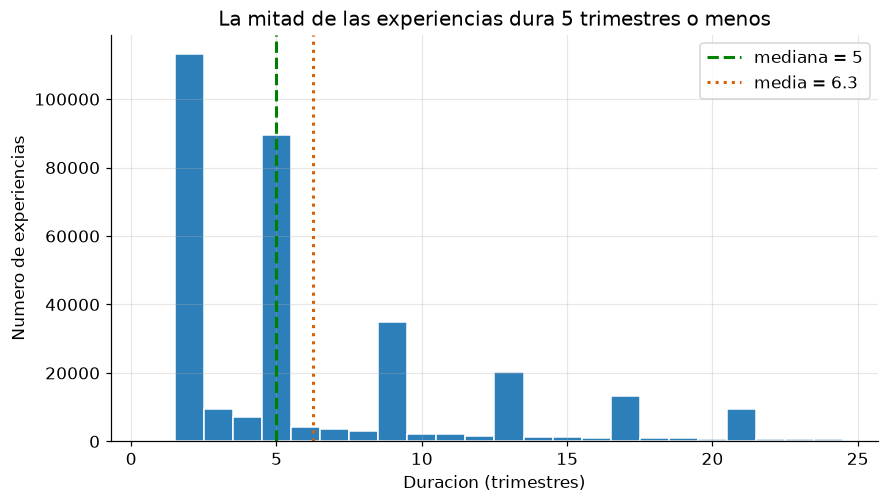

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
s = num["dur_q"].dropna()
ax.hist(s, bins=np.arange(0.5, 25.5, 1), color="#2c7fb8", edgecolor="white")
ax.axvline(s.median(), color="green", ls="--", lw=2, label=f"mediana = {s.median():.0f}")
ax.axvline(s.mean(), color="#d95f02", ls=":", lw=2, label=f"media = {s.mean():.1f}")
ax.set_title("La mitad de las experiencias dura 5 trimestres o menos")
ax.set_xlabel("Duracion (trimestres)")
ax.set_ylabel("Numero de experiencias")
ax.legend()
guardar(fig, "01_dur_q_hist.png"); plt.show()

figura -> docs\explicacion\report\02_n_skills_essential_hist.png


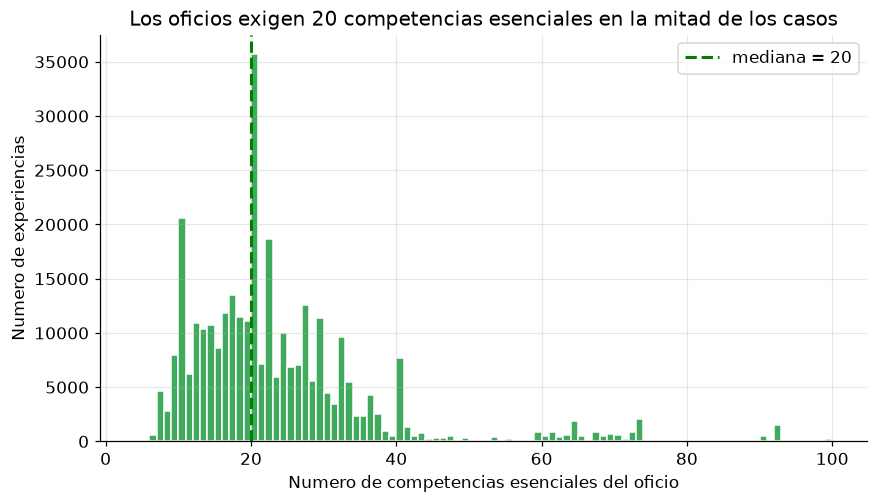

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.8))
s = num["n_skills_essential"].dropna()
ax.hist(s, bins=range(int(s.min()), int(s.max()) + 2), color="#41ab5d", edgecolor="white")
ax.axvline(s.median(), color="green", ls="--", lw=2, label=f"mediana = {s.median():.0f}")
ax.set_title("Los oficios exigen 20 competencias esenciales en la mitad de los casos")
ax.set_xlabel("Numero de competencias esenciales del oficio")
ax.set_ylabel("Numero de experiencias")
ax.legend()
guardar(fig, "02_n_skills_essential_hist.png"); plt.show()

figura -> docs\explicacion\report\03_dur_q_boxplot.png


C:\Users\ASUS\AppData\Local\Temp\ipykernel_17000\3435718770.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot([s], vert=False, widths=0.5, patch_artist=True,


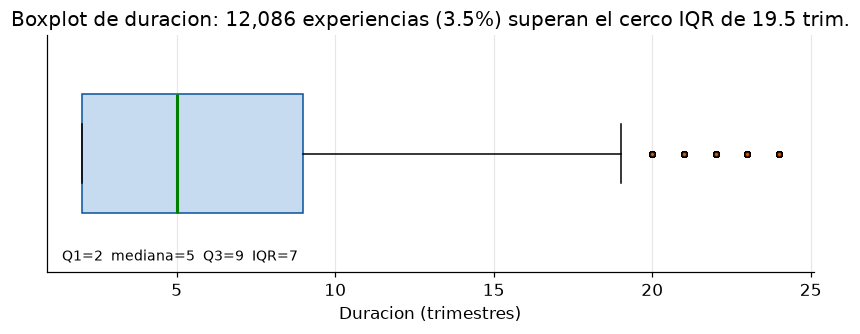

In [7]:
fig, ax = plt.subplots(figsize=(9, 2.8))
s = num["dur_q"].dropna()
q1, q3 = s.quantile(.25), s.quantile(.75)
iqr = q3 - q1
fence = q3 + 1.5 * iqr
n_out = int((s > fence).sum())
bp = ax.boxplot([s], vert=False, widths=0.5, patch_artist=True,
                boxprops=dict(facecolor="#c6dbef", color="#08519c"),
                medianprops=dict(color="green", lw=2),
                flierprops=dict(marker="o", markerfacecolor="#d95f02",
                                markersize=3, alpha=0.5))
ax.set_yticks([])
ax.set_title(f"Boxplot de duracion: {n_out:,} experiencias (3.5%) superan el cerco IQR de {fence:.1f} trim.")
ax.set_xlabel("Duracion (trimestres)")
ax.annotate(f"Q1={q1:.0f}  mediana={s.median():.0f}  Q3={q3:.0f}  IQR={iqr:.0f}",
            xy=(0.02, 0.05), xycoords="axes fraction", fontsize=9)
guardar(fig, "03_dur_q_boxplot.png"); plt.show()

figura -> docs\explicacion\report\04_categoricas_barras.png


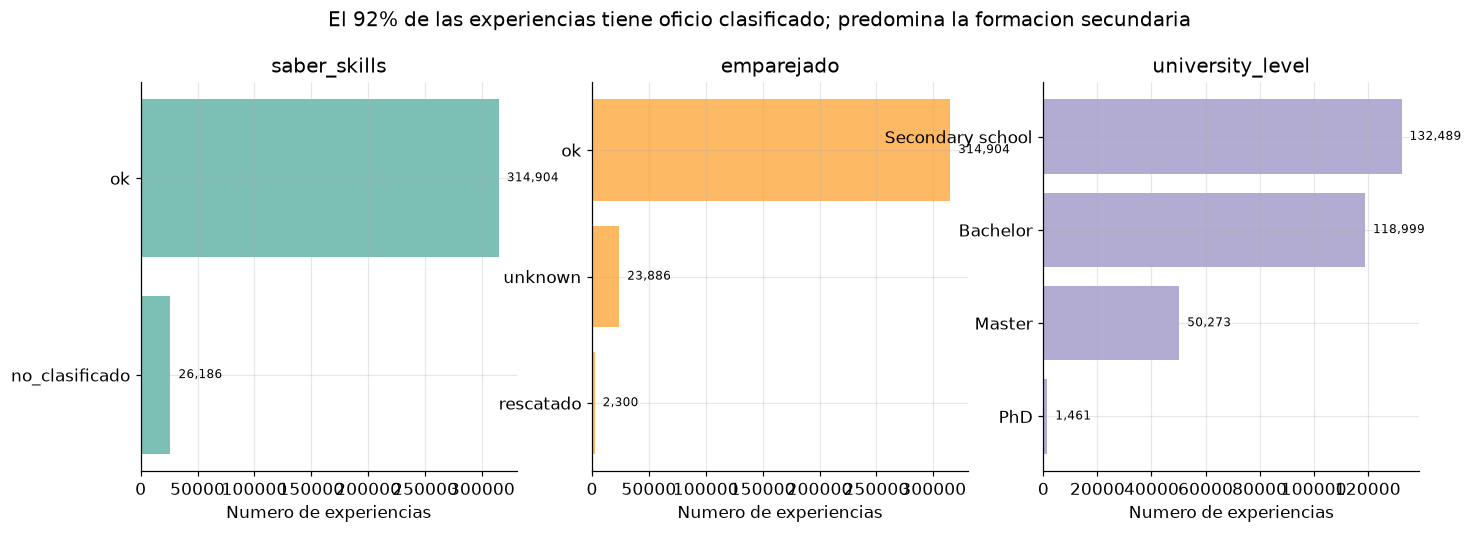

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, c, color in zip(axes, ["saber_skills", "emparejado", "university_level"],
                        ["#7bbfb5", "#fdb863", "#b2abd2"]):
    vc = df[c].value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color=color)
    ax.set_title(c)
    ax.set_xlabel("Numero de experiencias")
    for i, v in enumerate(vc.values[::-1]):
        ax.text(v, i, f"  {v:,}", va="center", fontsize=8)
fig.suptitle("El 92% de las experiencias tiene oficio clasificado; predomina la formacion secundaria", y=1.02)
guardar(fig, "04_categoricas_barras.png"); plt.show()

figura -> docs\explicacion\report\05_top_oficios.png


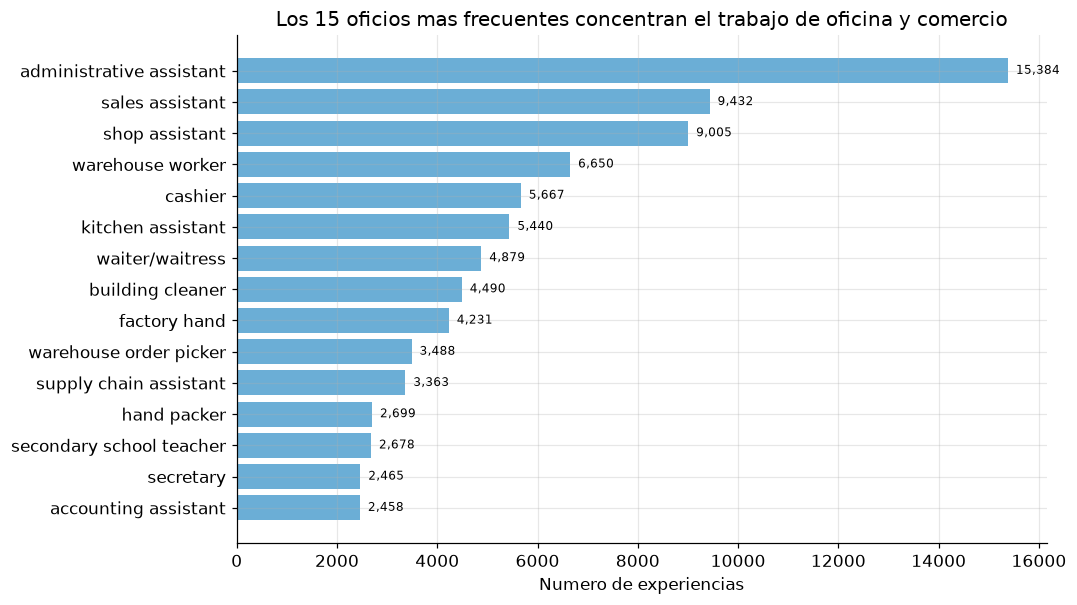

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 6))
vc = df.loc[ok, "occupation_label"].value_counts().head(15)
ax.barh(vc.index[::-1], vc.values[::-1], color="#6baed6")
ax.set_title("Los 15 oficios mas frecuentes concentran el trabajo de oficina y comercio")
ax.set_xlabel("Numero de experiencias")
for i, v in enumerate(vc.values[::-1]):
    ax.text(v, i, f"  {v:,}", va="center", fontsize=8)
guardar(fig, "05_top_oficios.png"); plt.show()

## 3. Análisis bivariado

Relación de `dur_q` con el área ocupacional y el nivel educativo, demanda de competencias frente a duración,
y tasa de reincidencia por área (mediana por grupo, no media).

C:\Users\ASUS\AppData\Local\Temp\ipykernel_17000\1447536820.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([data[i] for i in orden], vert=False, tick_labels=[grupos[i] for i in orden],


figura -> docs\explicacion\report\06_dur_q_por_area.png


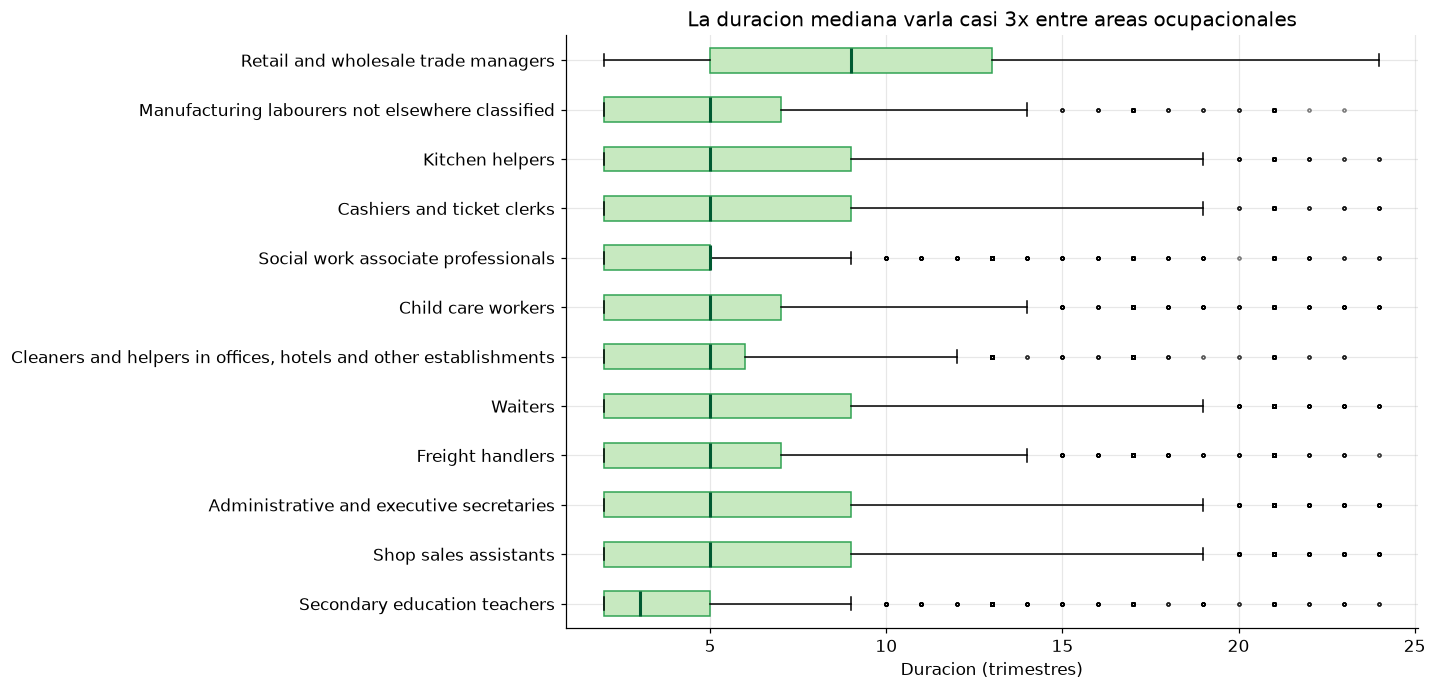

In [10]:
grupos = df.loc[ok, "isco_group_label"].value_counts().head(12).index
data = [df.loc[ok & df["isco_group_label"].eq(g), "dur_q"].dropna() for g in grupos]
orden = np.argsort([d.median() for d in data])
fig, ax = plt.subplots(figsize=(10, 7))
ax.boxplot([data[i] for i in orden], vert=False, tick_labels=[grupos[i] for i in orden],
           patch_artist=True, boxprops=dict(facecolor="#c7e9c0", color="#31a354"),
           medianprops=dict(color="#005a32", lw=2), flierprops=dict(markersize=2, alpha=0.3))
ax.set_title("La duracion mediana varIa casi 3x entre areas ocupacionales")
ax.set_xlabel("Duracion (trimestres)")
guardar(fig, "06_dur_q_por_area.png"); plt.show()

figura -> docs\explicacion\report\07_scatter_essential_duracion.png


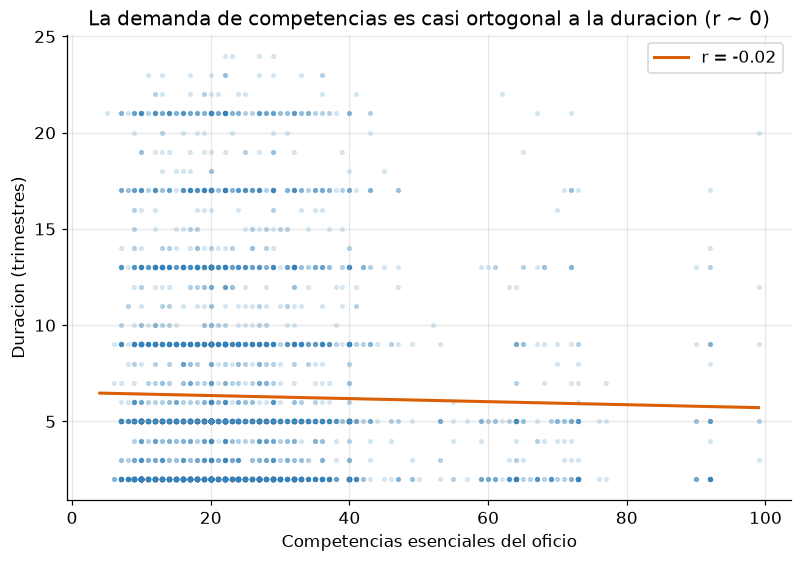

In [11]:
x = num["n_skills_essential"]
y = num["dur_q"]
m = x.notna() & y.notna()
r = np.corrcoef(x[m], y[m])[0, 1]
b, a = np.polyfit(x[m], y[m], 1)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(x[m].sample(min(6000, int(m.sum())), random_state=SEED), y[m].sample(min(6000, int(m.sum())), random_state=SEED),
           s=6, alpha=0.15, color="#3182bd")
xs = np.linspace(x[m].min(), x[m].max(), 50)
ax.plot(xs, a + b * xs, color="#d95f02", lw=2, label=f"r = {r:.2f}")
ax.set_title("La demanda de competencias es casi ortogonal a la duracion (r ~ 0)")
ax.set_xlabel("Competencias esenciales del oficio")
ax.set_ylabel("Duracion (trimestres)")
ax.legend()
guardar(fig, "07_scatter_essential_duracion.png"); plt.show()

figura -> docs\explicacion\report\08_reincidencia_por_area.png


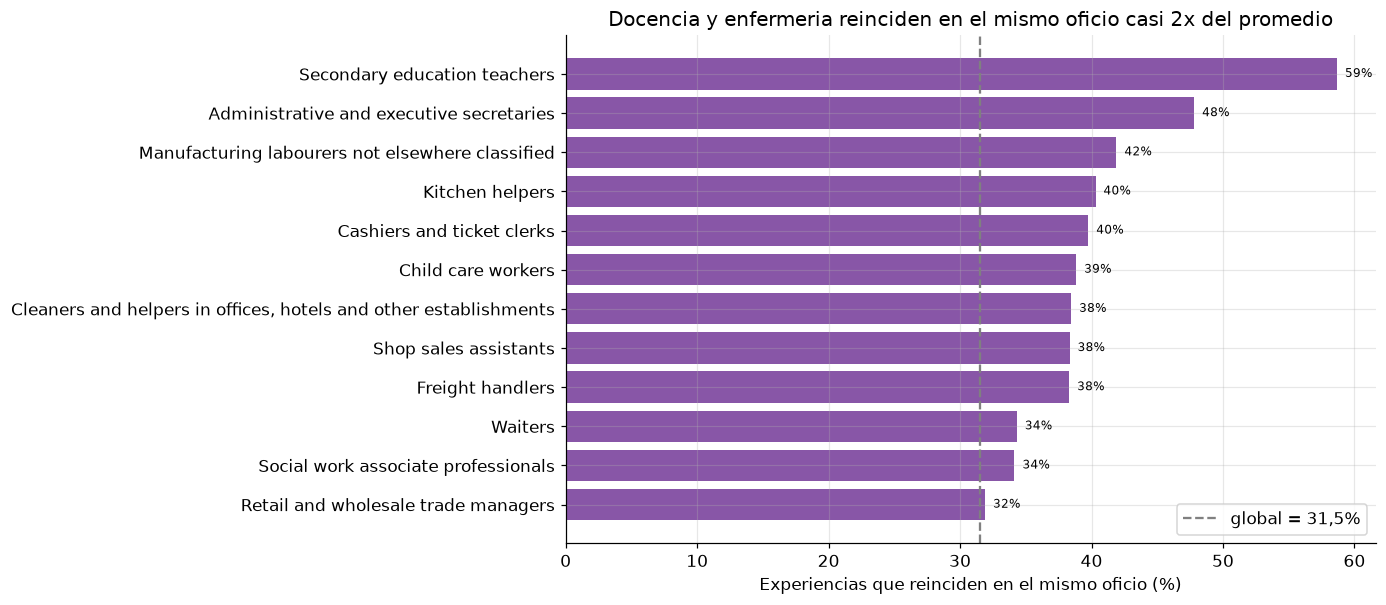

In [12]:
t = pd.crosstab(df.loc[ok, "isco_group_label"], NUM["veces_ese_oficio"][ok] > 1, normalize="index")
t.columns = ["no reincide", "reincide"]
t = t[t.index.isin(df.loc[ok, "isco_group_label"].value_counts().head(12).index)].sort_values("reincide")
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.barh(t.index, t["reincide"] * 100, color="#8856a7")
ax.axvline(31.5, color="gray", ls="--", lw=1.5, label="global = 31,5%")
ax.set_title("Docencia y enfermeria reinciden en el mismo oficio casi 2x del promedio")
ax.set_xlabel("Experiencias que reinciden en el mismo oficio (%)")
ax.legend()
for i, v in enumerate(t["reincide"] * 100):
    ax.text(v, i, f"  {v:.0f}%", va="center", fontsize=8)
guardar(fig, "08_reincidencia_por_area.png"); plt.show()

## 4. Análisis multivariado

Correlaciones simultáneas, matriz de dispersión y **auditoría de redundancia**: qué columnas son
información nueva y cuáles son la misma variable repartida.

figura -> docs\explicacion\report\09_heatmap_correlaciones.png


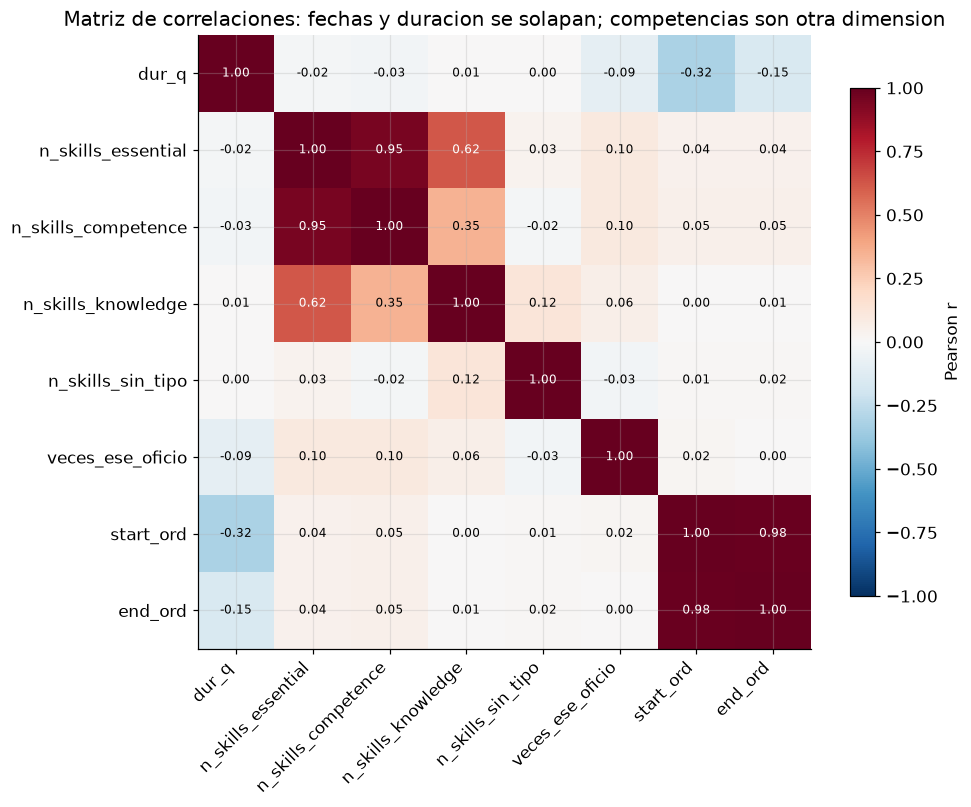

In [13]:
cols = ["dur_q", "n_skills_essential", "n_skills_competence", "n_skills_knowledge",
        "n_skills_sin_tipo", "veces_ese_oficio", "start_ord", "end_ord"]
corr = num[cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black", fontsize=8)
ax.set_title("Matriz de correlaciones: fechas y duracion se solapan; competencias son otra dimension")
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
guardar(fig, "09_heatmap_correlaciones.png"); plt.show()

figura -> docs\explicacion\report\10_matriz_dispersion.png


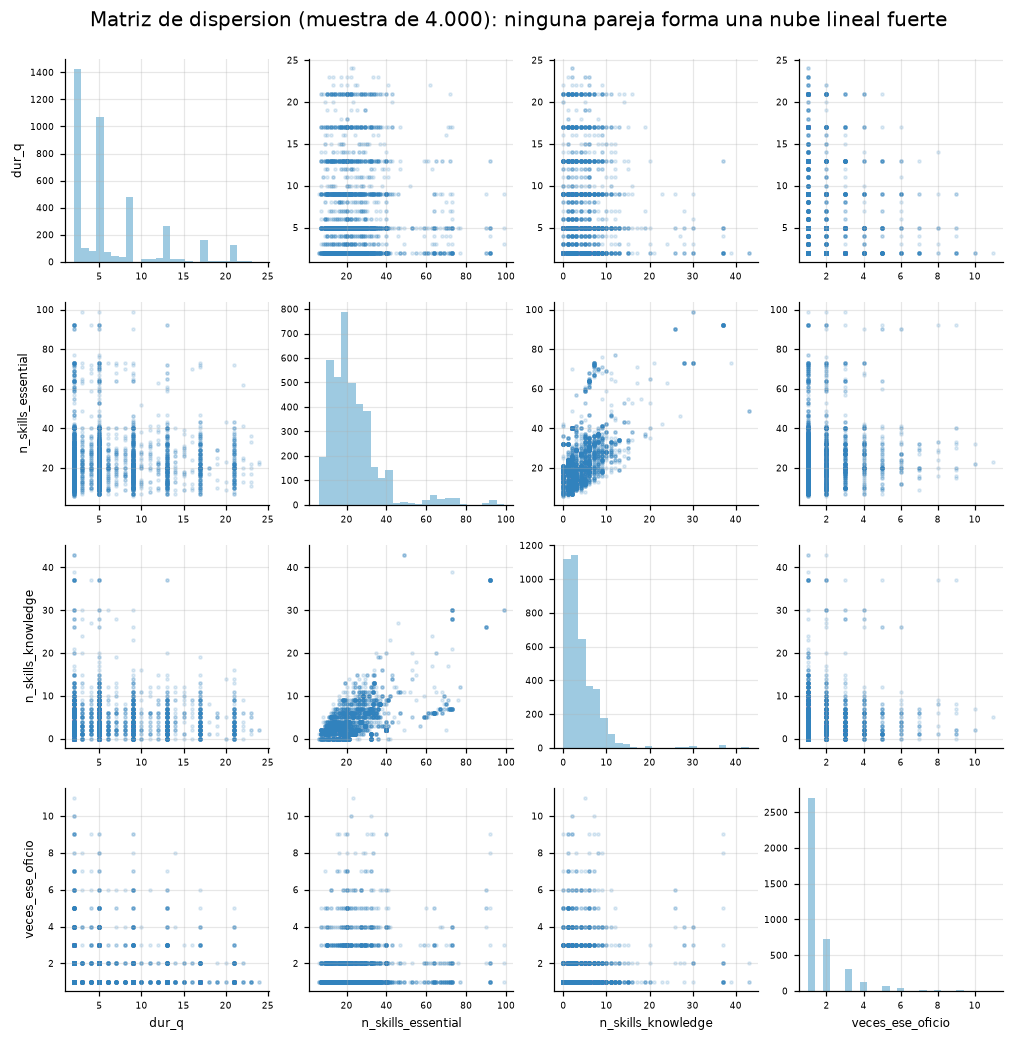

In [14]:
sel = ["dur_q", "n_skills_essential", "n_skills_knowledge", "veces_ese_oficio"]
datos = num[sel].dropna().sample(min(4000, int(num[sel].dropna().shape[0])), random_state=SEED)
fig, axes = plt.subplots(len(sel), len(sel), figsize=(11, 11))
for i, ci in enumerate(sel):
    for j, cj in enumerate(sel):
        ax = axes[i, j]
        if i == j:
            ax.hist(datos[ci], bins=25, color="#9ecae1")
        else:
            ax.scatter(datos[cj], datos[ci], s=4, alpha=0.15, color="#3182bd")
        if i == len(sel) - 1:
            ax.set_xlabel(cj, fontsize=8)
        if j == 0:
            ax.set_ylabel(ci, fontsize=8)
        ax.tick_params(labelsize=6)
fig.suptitle("Matriz de dispersion (muestra de 4.000): ninguna pareja forma una nube lineal fuerte", y=0.92)
guardar(fig, "10_matriz_dispersion.png"); plt.show()

In [15]:
print("=== Auditoria de redundancia ===")
por_oficio = df.loc[ok].groupby("occupation_code")["n_skills_essential"].nunique()
print("n_skills_essential por occupation_code -> valores distintos por oficio:",
      por_oficio.value_counts().to_dict(), "(1 = determinista del oficio)")
ess = NUM["n_skills_essential"]
grupo_media = ess[ok].groupby(df.loc[ok, "isco_group"]).transform("mean")
eta2 = 1 - ((ess[ok] - grupo_media) ** 2).sum() / ((ess[ok] - ess[ok].mean()) ** 2).sum()
print(f"eta^2 del grupo ISCO sobre n_skills_essential: {eta2:.3f} (el grupo explica ~{eta2*100:.0f}%)")
print("corr(competence, knowledge) =",
      round(NUM["n_skills_competence"].corr(NUM["n_skills_knowledge"]), 3), "(son un reparto de essential)")
print("Banderas dentro de las filas ok ->",
      {c: int(df.loc[ok, c].nunique()) for c in ["es_unknown_ocupacion", "es_rescatado", "es_vigente"]})
print("emparejado dentro de ok ->", df.loc[ok, "emparejado"].value_counts().to_dict(),
      "(colapsa a una sola categoria)")

=== Auditoria de redundancia ===
n_skills_essential por occupation_code -> valores distintos por oficio: {1: 2826} (1 = determinista del oficio)
eta^2 del grupo ISCO sobre n_skills_essential: 0.728 (el grupo explica ~73%)
corr(competence, knowledge) = 0.348 (son un reparto de essential)
Banderas dentro de las filas ok -> {'es_unknown_ocupacion': 1, 'es_rescatado': 1, 'es_vigente': 2}
emparejado dentro de ok -> {'ok': 314904} (colapsa a una sola categoria)


**Lectura.** `start_ord` y `end_ord` correlacionan 0,99 (son la misma línea de tiempo) y `dur_q` correlaciona
−0,32 con `start_ord`: las experiencias más recientes son más cortas (censura por la derecha). Los contadores
de competencias forman un bloque aparte, casi ortogonal a las fechas: describen **qué exige el puesto**, no
**cuándo** ocurrió. `n_skills_essential` es determinista de `occupation_code` (η²≈0,73 con el grupo ISCO) y
`competence`+`knowledge` son un reparto del total, no variables independientes.

## 5. Análisis de las competencias ESCO (eje central del proyecto)

Las seis columnas de competencias miden los **requisitos del oficio**. Aquí se explora la demanda
(`n_skills_essential`), el reparto saber/saber-hacer (ratio) y el contenido real de las listas `skills`.

figura -> docs\explicacion\report\11_ratio_saber_hacer.png


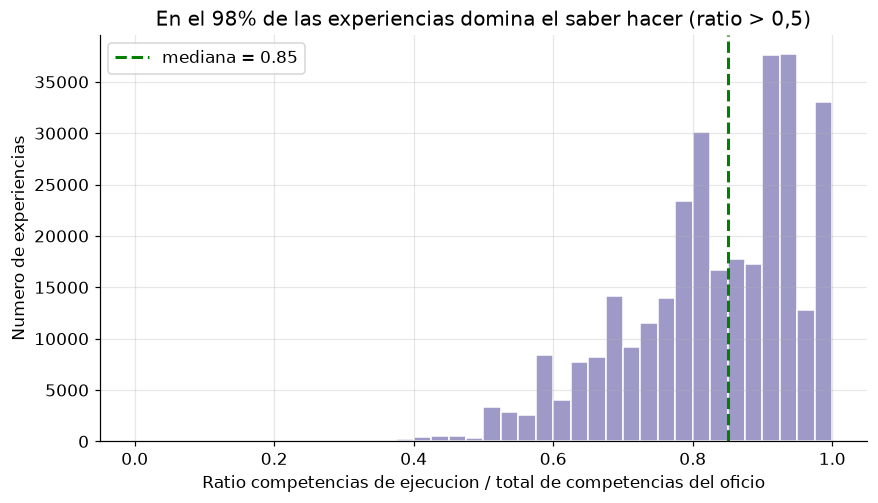

In [16]:
ratio = (NUM["n_skills_competence"] / NUM["n_skills_essential"]).dropna()
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(ratio, bins=40, color="#9e9ac8", edgecolor="white")
ax.axvline(ratio.median(), color="green", ls="--", lw=2, label=f"mediana = {ratio.median():.2f}")
ax.set_title("En el 98% de las experiencias domina el saber hacer (ratio > 0,5)")
ax.set_xlabel("Ratio competencias de ejecucion / total de competencias del oficio")
ax.set_ylabel("Numero de experiencias")
ax.legend()
guardar(fig, "11_ratio_saber_hacer.png"); plt.show()

figura -> docs\explicacion\report\12_demanda_por_area.png


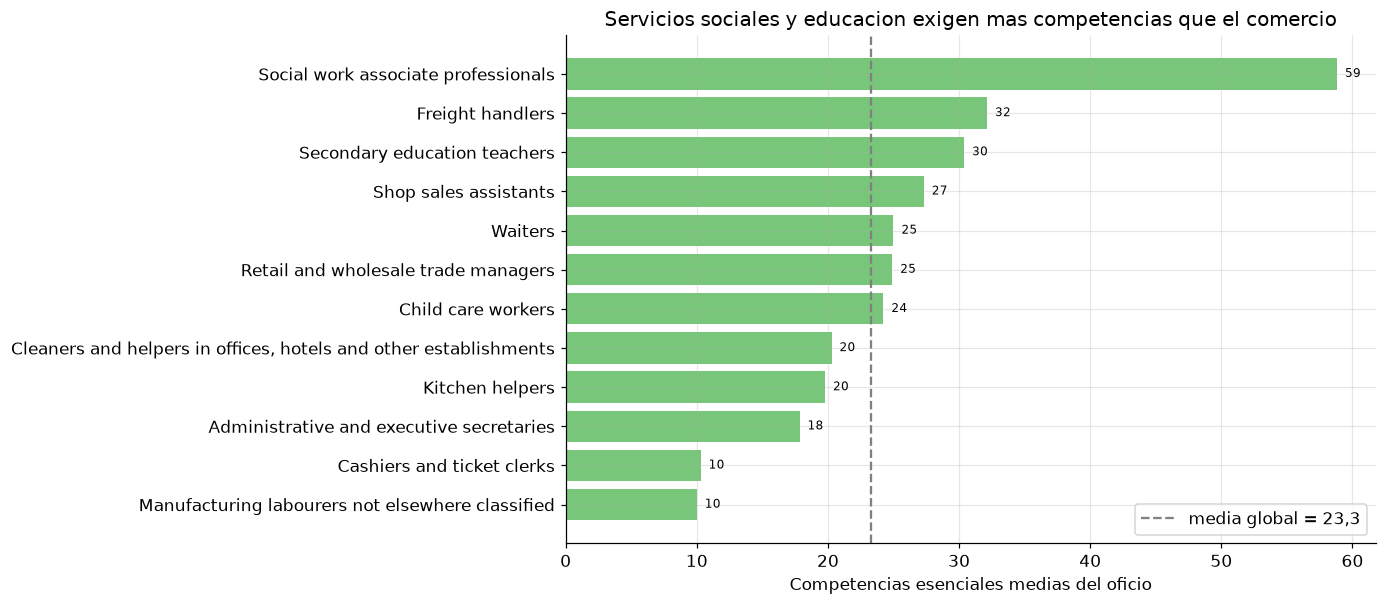

In [17]:
g = df.loc[ok].assign(ess=NUM["n_skills_essential"][ok])
g = g[g["isco_group_label"].isin(g["isco_group_label"].value_counts().head(12).index)]
media = g.groupby("isco_group_label")["ess"].mean().sort_values()
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.barh(media.index, media.values, color="#78c679")
ax.axvline(23.3, color="gray", ls="--", lw=1.5, label="media global = 23,3")
ax.set_title("Servicios sociales y educacion exigen mas competencias que el comercio")
ax.set_xlabel("Competencias esenciales medias del oficio")
ax.legend()
for i, v in enumerate(media.values):
    ax.text(v, i, f"  {v:.0f}", va="center", fontsize=8)
guardar(fig, "12_demanda_por_area.png"); plt.show()

In [18]:
top = (df.loc[ok].assign(ess=NUM["n_skills_essential"][ok])
       .groupby("occupation_label")["ess"].agg(["mean", "count"]))
top = top[top["count"] >= 200].sort_values("mean", ascending=False).head(10)
print("=== Oficios mas exigentes (>=200 experiencias) ===")
print(top.round(1).to_string())
print()
sk = df.loc[ok, "skills"].replace("", np.nan).dropna()
todas = pd.Series([x for fila in sk for x in fila.split("|")])
vc = todas.value_counts()
print("Relaciones (experiencia, competencia) de ejecucion:", f"{len(todas):,}")
print("Competencias distintas usadas:", f"{vc.size:,}")
print("Top-10 competencias mas frecuentes y su cobertura:")
for nombre, n in vc.head(10).items():
    print(f"   {n:>7,}  {nombre}")
print(f"   Top-10 cubren {100 * vc.head(10).sum() / len(todas):.1f}% de los pares")

=== Oficios mas exigentes (>=200 experiencias) ===
                                           mean  count
occupation_label                                      
clinical psychologist                      99.0    232
nurse responsible for general care         92.0   1498
physiotherapist                            90.0    467
child day care worker                      73.0   1332
speech and language therapist              73.0    397
youth worker                               72.0    693
specialist nurse                           70.0    310
social work practice educator              69.0    219
residential childcare worker               67.0    731
residential home young people care worker  64.0   1727

Relaciones (experiencia, competencia) de ejecucion: 6,082,711
Competencias distintas usadas: 8,485
Top-10 competencias mas frecuentes y su cobertura:
    40,438  identify customer's needs
    39,688  use different communication channels
    38,377  provide customer follow-up services
   

**Lectura.** La demanda de competencias es muy desigual: de 4 a 99 por oficio, con mediana 20 y una cola de
perfiles «saber-intensivos» (psicólogo clínico 99, enfermería 92). El *saber hacer* domina en casi todo el
dataset (ratio > 0,5 en 309.709 de 314.904 registros). El vocabulario de competencias es de cola larga: las 10
más frecuentes cubren apenas el 5,6% de los pares, lo que refuerza que la unidad útil de análisis es el
**oficio**, no un «perfil promedio».

## 6. Diagnóstico de calidad y decisiones heredadas

Estado de nulos, respeto de la regla **vacío ≠ 0**, censura `Present`, pluriempleo y las filas que quedan
fuera de la matriz `X`.

In [19]:
print("=== Nulos y vacios ===")
nulos = df.isna().sum()
print("Columnas con nulos:", {c: int(v) for c, v in nulos.items() if v > 0})
print()
ess = NUM["n_skills_essential"]
print("Regla vacio != 0 -> el contador esta vacio exactamente cuando saber_skills != ok:",
      bool((ess.isna() == ~ok).all()))
print("Contadores iguales a 0 en filas clasificadas (debe ser 0 para essential):",
      int((ess == 0).sum()))
print("Suma de buckets == essential (clasificadas):",
      bool((NUM["n_skills_competence"] + NUM["n_skills_knowledge"] + NUM["n_skills_sin_tipo"])[ok].eq(ess[ok]).all()))
print()
print("=== Censura y pluriempleo ===")
print("Empleos vigentes (end_date == 'Present', es_vigente):", f"{int(df['end_date'].eq('Present').sum()):,}")
periodos = df[["resume_id", "start_date", "end_date"]].drop_duplicates().shape[0]
print("Filas:", f"{len(df):,}", "| periodos distintos (persona, inicio, fin):", f"{periodos:,}",
      "| filas de mas:", f"{len(df) - periodos:,}")
print()
print("=== Filas que quedan fuera de X ===")
print("no_clasificado:", f"{int((~ok).sum()):,}", f"({100 * (~ok).mean():.2f}%)",
      "-> son las que no tienen oficio y saldrian de la matriz X")

=== Nulos y vacios ===
Columnas con nulos: {'university_level': 37868, 'occupation_code': 26186, 'occupation_label': 26186, 'isco_group': 23886, 'isco_group_label': 23886, 'isco_level': 23886, 'n_skills_essential': 26186, 'n_skills_competence': 26186, 'n_skills_knowledge': 26186, 'n_skills_sin_tipo': 26186, 'veces_ese_oficio': 26186, 'skills': 26188, 'knowledge': 59153, 'sin_tipo': 338144, 'end_ord': 18956, 'dur_q': 18956}

Regla vacio != 0 -> el contador esta vacio exactamente cuando saber_skills != ok: True
Contadores iguales a 0 en filas clasificadas (debe ser 0 para essential): 0
Suma de buckets == essential (clasificadas): True

=== Censura y pluriempleo ===
Empleos vigentes (end_date == 'Present', es_vigente): 18,956
Filas: 341,090 | periodos distintos (persona, inicio, fin): 323,742 | filas de mas: 17,348

=== Filas que quedan fuera de X ===
no_clasificado: 26,186 (7.68%) -> son las que no tienen oficio y saldrian de la matriz X


figura -> docs\explicacion\report\13_calidad_ok_vs_noclasi.png


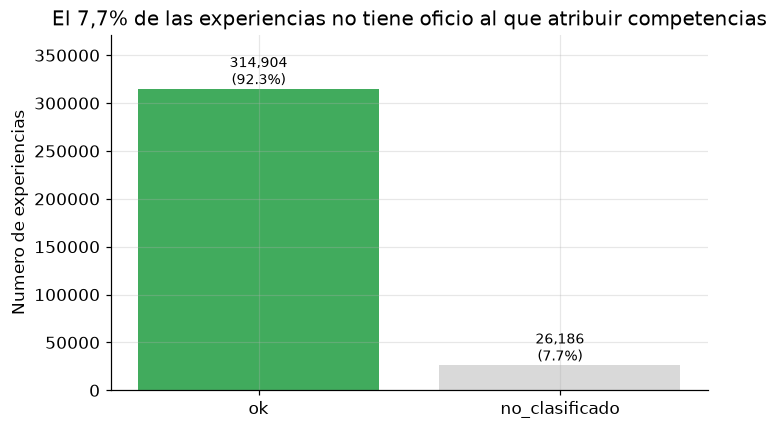

In [20]:
fig, ax = plt.subplots(figsize=(7, 4.2))
vc = df["saber_skills"].value_counts()
b = ax.bar(vc.index, vc.values, color=["#41ab5d", "#d9d9d9"])
ax.set_title("El 7,7% de las experiencias no tiene oficio al que atribuir competencias")
ax.set_ylabel("Numero de experiencias")
for rect, v in zip(b, vc.values):
    ax.text(rect.get_x() + rect.get_width() / 2, v, f"{v:,}\n({100*v/len(df):.1f}%)",
            ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, vc.max() * 1.18)
guardar(fig, "13_calidad_ok_vs_noclasi.png"); plt.show()

**Lectura.** No hay nulos «sucios»: los vacíos son estructurales y están gobernados por banderas. La regla
**vacío ≠ 0** se cumple (los contadores están vacíos exactamente en las 26.186 filas `no_clasificado`, nunca
en 0). La censura `Present` (18.956 empleos vigentes) se marca con `es_vigente` sin inventar fecha de fin.
El pluriempleo (17.348 filas de más sobre 323.742 periodos) se **conserva**: son cargos simultáneos o
transiciones dentro del mismo trimestre, no duplicados.

## Hallazgos accionables

Cada hallazgo conecta una evidencia (cifra/gráfico) con una implicación para la fase de **minería de
secuencias** (construcción de `S_p` y descubrimiento de patrones de transición).

**H1. La cobertura ESCO gobierna el universo analizable.**
*Evidencia:* 314.904 experiencias `ok` (92,3%) frente a 26.186 `no_clasificado` (7,7%). *Implicación:* la
construcción de `S_p` debe decidir el tratamiento de `unknown` (deuda D1): excluirlas o analizarlas como
segmento propio; hoy serían un hueco que rompe la cadena de transición.

**H2. La trayectoria típica es corta y la cola larga ya fue recortada.**
*Evidencia:* mediana 5 trimestres, Q3 9, máximo 24 (fig. 01 y 03). *Implicación:* las secuencias serán
cortas y dominadas por 1–3 empleos, lo que favorece técnicas de patrones secuenciales con umbrales de soporte
bajos; recordar que evaluar «estabilidad laboral» sobre este recorte subestima los extremos por diseño.

**H3. La reincidencia es un tercio del dataset.**
*Evidencia:* 31,5% de las experiencias ocurren en un oficio ya ejercido por la misma persona (`veces_ese_oficio > 1`, fig. 08). *Implicación:* `S_p` debe incorporar la repetición como señal (retorno al oficio), no
como fila a deduplicar; docencia y enfermería reinciden casi el doble del promedio.

**H4. Duración y demanda de competencias son dimensiones ortogonales.**
*Evidencia:* r ≈ −0,02 entre `dur_q` y `n_skills_essential` (fig. 07 y 09). *Implicación:* para caracterizar
transiciones se necesitan **ambas** dimensiones; ninguna resume a la otra, y el PCA no comprime (la ortogonalidad
es, justamente, la condición para que no sirva).

**H5. El «saber hacer» domina y el vocabulario es de cola larga.**
*Evidencia:* ratio ejecución/total > 0,5 en 309.709 de 314.904 registros; las 10 competencias más frecuentes
cubren solo 5,6% de los pares (fig. 11). *Implicación:* el salto de competencias entre contratos consecutivos
se mide mejor con el índice de Jaccard sobre listas que con conteos; el oficio —no el «perfil promedio»— es la
unidad de análisis.

**H6. Hay redundancia estructural que debe declararse antes de modelar.**
*Evidencia:* `n_skills_essential` es determinista de `occupation_code`; `competence`+`knowledge` reparten
`essential`; tras el recorte, `es_unknown_ocupacion`/`es_rescatado`/`emparejado` quedan constantes dentro de
la `X`. *Implicación:* elegir una sola representación del oficio (número **o** one-hot) y excluir las banderas
constantes, para no inflar features ni engañar la importancia de variables.